<div style="background-color:#f4f4f8; padding: 20px; border-radius: 10px; border-left: 5px solid #2c3e50;">
    <h1 style="color:#2c3e50; text-align:center;">PROJET : COUVERTURE DE RISQUE DE TAUX (PRE-HEDGING)</h1>
    <h3 style="color:#7f8c8d; text-align:center;">Université Lumière Lyon 2</h3>
    <p style="text-align:center;"><strong>Auteurs :</strong> Baptiste Juillard, Célian Dieppedalle-Lefebvre, Léa Goudier</p>
</div>

<br>

#### CONTEXTE FINANCIER :

Une entreprise souhaite émettre une obligation dans le futur (ex: dans 3 mois).
Elle craint une hausse des taux d'intérêt entre aujourd'hui (t=0) et la date d'émission (t=1).

#### LE RISQUE :

Si les taux montent :
1. Les investisseurs exigeront un rendement plus élevé.
2. Le prix de l'obligation à taux fixe baissera.
3. L'entreprise recevra moins de cash à l'émission (ou devra payer un coupon plus cher).

#### LA STRATÉGIE (HEDGING) :

Pour se protéger, l'entreprise vend des contrats Futures (Position Short) aujourd'hui.
- Si les taux montent -> Le prix des Futures baisse -> Gain sur la position Short.
- Ce gain viendra compenser la perte sur l'émission obligataire.

#### OBJECTIF DU CODE :

1. Calculer la sensibilité de la dette et du contrat Future (fonction Sensi).
2. Déterminer le Ratio de Couverture (Calculautomatique).
3. Simuler différents scénarios de chocs de taux pour vérifier l'efficacité (Tableauscenarios).

In [2]:
import numpy as np
import numpy_financial as npf
import pandas as pd
import matplotlib.pyplot as plt


=== FLUX A COUVRIR===


Montant de la dette à couvrir :   1000000
Montant du taux de coupon :  1
Maturité de la dette : (années)  2
Taux actuel de marché :  1
Quel choc de taux est attendu :   1


----------------------------------------
 Recommandation, choisir ce contrat : : Euro-Schatz (Court Terme)
 Raison : Votre dette est à court terme (< 3.5 ans)
----------------------------------------
Sensibilité calculée Dette (SO)  : 1.94
Sensibilité calculée Future (SF) : 1.90
Nombre de contrats à vendre : 9


C:\Users\bapti\anaconda3\envs\coursbaptiste\Lib\site-packages\numpy_financial\_financial.py:531: RuntimeWarning: invalid value encountered in divide
  fact = np.where(rate == 0, nper, (1+rate*when)*(temp-1)/rate)


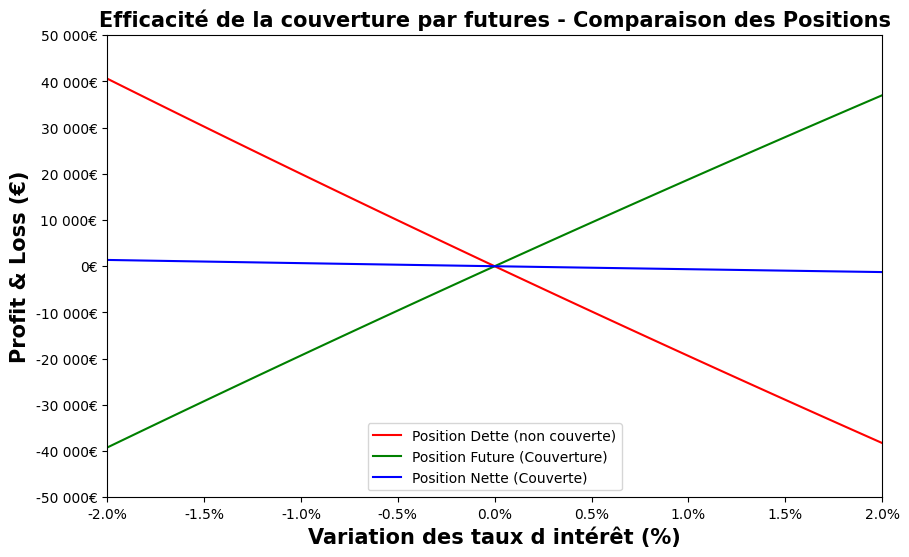


TABLEAU DES SCÉNARIOS DE COUVERTURE EN FONCTION DES DIFFERENTS CHOCS DE TAUX
On se place au jour de l'émission. Combien ai-je économisé grâce à mes futures ?


Scénario taux,P&L Dette (€),P&L Futures (€),P&L Total (€),Efficacité (%)
-2.00%,"40,608","-39,248","1,360",96.7
-1.00%,"20,000","-19,332",668,96.7
+0.00%,0,0,0,N/A
+1.00%,"-19,416","18,772",-644,96.7
+2.00%,"-38,269","37,004","-1,265",96.7


In [6]:
def DemanderFlux(message_perso):
    """
    Fonction que nous utilisons tout au long de notre code, 
    elle permet de demander à l'utilisateur un flux qui est bien un nombre (qui sera transformée en float), 
    la fonction permet d'éviter les erreurs de frappes au sein de notre fonction générale
    """
    
    while True:
        try:
            flux=float(input(message_perso))
            break
        except ValueError:
            print("Erreur, renvoie un nombre valide ")
    return flux

#=> on peut également l'utiliser pour le future car c'est un contrat notionnelle qui se comporte comme une obligation fictive
def ValeurActuellePV(coupon,nominal,rm,t):
    '''
    avec coupon = taux de coupon
    nominal= la valeur faciale de l'obligation
    rm = le taux de marché
    Calcule la valeur actuelle / le prix d'une obligation ou d'un contrat notionnel.
    Utilise la formule des flux actualisés.
    '''
    montant_coupon = coupon * nominal
    Price = npf.pv(rm,t,montant_coupon,nominal)
    return abs(Price)


def Sensi(coupon,nominal,rm,t,var):
    '''
    Cette fonction calcule la variation de prix d'une obligation en fonction de la variation de taux d'intérêt du marché 
    avec 
    coupon = taux de coupon
    nominal = valeur nominal
    rm = taux de marché
    t = maturité 
    var => variation de marché
    Retourne : (Sensibilité, Prix Initial)
    '''

    #Prix initial / actuel
    prix1=ValeurActuellePV(coupon, nominal, rm, t)
    #Prix après une variation de x%
    prix2=ValeurActuellePV(coupon, nominal, rm + var, t)
   
    variation_prix  = (prix1-prix2)
    sensi = (variation_prix/ prix1)/var
    
    return sensi, prix1

def ProtectionFuture(maturite_dette):
    """
    Cette fonction donne les 3 possibillités de couvertures que je propose dans mon exemple
    Maturité : 
    2ans = Shatz  100k 6%
    5 ans = OAT france FOAM 100 k 6%
    10 ans = OAT france FOAT 100 k 6%

    De plus, elle selectionne le contrat future le plus adaptée en fonction de la maturité de la dette à couvrir.
    """
    
    contrat = {
        "1": {"nom": "Euro-Schatz (Court Terme)", "maturite": 2,  "coupon": 0.06, "nominal": 100000},
        "2": {"nom": "Mid-Term Euro-OAT Futures ",   "maturite": 5,  "coupon": 0.06, "nominal": 100000},
        "3": {"nom": "Euro-OAT Futures ",    "maturite": 10, "coupon": 0.06, "nominal": 100000}
    }
    
    if maturite_dette < 3.5 :
        choix = "1"
        raison = "Votre dette est à court terme (< 3.5 ans)"
    elif 3.5 <= maturite_dette < 7.5 :
        choix = "2"
        raison = "Votre dette est à moyen terme (3.5 - 7.5 ans)"
    else :
        choix = "3"
        raison = "Votre dette est à long terme (< 7.5 ans)"
    
    selection = contrat[choix]
    print("-" * 40)
    print(f" Recommandation, choisir ce contrat : : {selection['nom']}")
    print(f" Raison : {raison}")
    print("-" * 40)
    return selection["nominal"],selection["coupon"],selection["maturite"]

## Fonctions de simulation et d'affichage graphique

def TableauScenarios(coupon_dette, nominal_dette, rm, maturite_dette,
                     coupon_future, nominal_future, maturite_future, N, prix_initial_dette, prix_initial_future):

    """
    Cette fonction génère un tableau de bord des scénarios de taux. 
    Cela permet de voir l'efficacité de notre couverture en cas de différents scénarios possible
    """
    
    scenarios = [-0.02, -0.01, 0, 0.01, 0.02]

    resultats = []
    for var in scenarios:
        nouveau_prix_dette = ValeurActuellePV(coupon_dette, nominal_dette, rm + var, maturite_dette)
        nouveau_prix_future = ValeurActuellePV(coupon_future, nominal_future, rm + var, maturite_future)
        
        pnl_dette = nouveau_prix_dette - prix_initial_dette
        pnl_future = (prix_initial_future - nouveau_prix_future) * N
        pnl_total = pnl_dette + pnl_future
        
        #création d'un dictionnaire 
        
        resultats.append({
            'Scénario taux': f"{var*100:+.2f}%",
            'P&L Dette (€)': f"{pnl_dette:,.0f}",
            'P&L Futures (€)': f"{pnl_future:,.0f}",
            'P&L Total (€)': f"{pnl_total:,.0f}",
            'Efficacité (%)': f"{(1 - abs(pnl_total)/abs(pnl_dette))*100:.1f}" if pnl_dette != 0 else "N/A"
        })
    
    df = pd.DataFrame(resultats)

    return df.style.hide()

def VisualisationEfficaciteCouverture(coupon_dette, nominal_dette, rm, maturite_dette, 
                                      coupon_future, nominal_future, maturite_future, N, prix_initial_dette, 
                                      prix_initial_future):
    """ Visualise l'efficacité de la couverture en comparant les 3 positions :
    Position Dette (non couverte)
    Position Future
    Position Nette (couverte)
    Pour tracer le graphique, la fonction reprend les données que l'utilisateur a indiqué dans l'interface
    """
    
    variations_taux = np.linspace(-0.02, 0.02, 100) 
    ''' Cela va créer l'axe X avec une plage de variation de taux de -2% à 2%'''
    
    pnl_dette_list = []
    pnl_future_list = []
    pnl_total_list = []
    '''listes pour socker les résultats'''
    

    for var in variations_taux:
        nouveau_prix_dette = ValeurActuellePV(coupon_dette, nominal_dette, rm + var, maturite_dette)
        nouveau_prix_future = ValeurActuellePV(coupon_future, nominal_future, rm + var, maturite_future)
        ''' Calcul du prix de l'obligation et du future avec le nouveau taux rm + var '''
        
        pnl_dette = nouveau_prix_dette - prix_initial_dette
        pnl_future = (prix_initial_future - nouveau_prix_future) * N
        pnl_total = pnl_dette + pnl_future
        ''' Calcul des PnL grâce aux nouveaux prix calculés plus haut '''
        
        pnl_dette_list.append(pnl_dette)
        pnl_future_list.append(pnl_future)
        pnl_total_list.append(pnl_total)
        ''' Listes pour stocker les résultats obtenus '''
        
    # Création du graphique
    
    plt.figure(figsize=(10, 6)) #Définit la taille de la figure
    plt.plot(variations_taux, pnl_dette_list, 'r', label='Position Dette (non couverte)') 
    plt.plot(variations_taux, pnl_future_list, 'g', label='Position Future (Couverture)')
    plt.plot(variations_taux, pnl_total_list, 'b', label='Position Nette (Couverte)')
    ''' Trace les courbes des 3 PnL '''
    
    plt.xlim(variations_taux.min(), variations_taux.max())
    ## On force l'axe X à coller exactement au minimum et maximum de vos données
    plt.xlabel('Variation des taux d intérêt (%)', fontsize=15, fontweight='bold')
    ## Nomme l'axe X en gras de taille 15
    plt.ylabel('Profit & Loss (€)', fontsize=15, fontweight='bold')
    ## Nomme l'axe Y en gras de taille 15
    plt.title('Efficacité de la couverture par futures - Comparaison des Positions', fontsize=15, fontweight='bold')
    ## Met un titre au graphique
    plt.legend() ## Fait apparaitre la légende

    ''' Gestion de l'axe X en pourcentage'''
    locs_x, _ = plt.xticks() ## on récupère les tirets de Python a mis automatiquement
    labels_x = [f"{x*100:.1f}%" for x in locs_x] ## on reformate le texte en pourcentage
    plt.xticks(locs_x, labels_x) ## On réapplique les mêmes tirets avec le nouveau texte

    '''Gestion de l'axe Y (Euros)'''
    locs_y, _ = plt.yticks() ## on récupère les tirets de Python a mis automatiquement
    labels_y = [f"{x:,.0f}€".replace(',', ' ') for x in locs_y] ## on reformate le texte en € en espacant les milliers
    plt.yticks(locs_y, labels_y) ## On réapplique les mêmes tirets avec le nouveau texte
    
    plt.show()
    
#Fonction principale :

def CalculAutomatique():
    '''
    Cette fonction vient calculer le nombre de contrat future à vendre pour se couvrir de la baisse des taux 
    on indique donc les paramètres de notre obligation et le chox de taux que l'on prévoit

    Interface utilisateur : Récupère les caractéristiques de la dette à émettre (Nominal, Coupon, Maturité) et les conditions de marché.
    Calculs : 
    - Détermine la sensuibilité et le prix de l'obligation (Dette)
    - Sélectionne le contrat future adéquat et calcule sa sensibilité 
    - Calcul le nombre de cointrat à vendre pour immuniser le portefeuille
    Visualisation : Génère un graphique comparant les positions nue, couverte et de couverture.
    Simulation : Produit un tableau de bord mesurant l'efficacité de la couverture face à différents chocs de taux.

    Reprise de la formule du cours avec SV = SO pour sensibilité de l'obligation
                                            SM = SF pour sensibilité du contrat future
    '''
    ##le /n permet de sauter une ligne pour la visibilité du code                                        
    print("\n=== FLUX A COUVRIR===")
    # emprunt obligataire 100M 2% sur 10 ans
    nominal_dette = DemanderFlux("Montant de la dette à couvrir :  ") # 100M
    coupon_dette = DemanderFlux("Montant du taux de coupon : ")/100
    maturite_dette = DemanderFlux("Maturité de la dette : (années) ")
    taux_marche = DemanderFlux("Taux actuel de marché : ")/100
    # variance entre deux dates => voir pour modifier
    var = DemanderFlux("Quel choc de taux est attendu :  ")/100

    # 1. On calcule la Sensibilité de l'obliogation => SO et le Prix initial => double entrée car double return dans la Funct se Sensi 
    #On calcule d'une part la sensibilité et d'une autre le prix de l'actif
    so_calcul, prix_o = Sensi(coupon_dette, nominal_dette, taux_marche, maturite_dette,var)
    
    # 2. Paramètres Future (Euro-Bund standard)
    nominal_future, coupon_future ,maturite_future = ProtectionFuture(maturite_dette)
    
    # 3. On calcule la Sensibilité du future et son prix => double entrée car double return dans la fonction Sensi 
    #On calcule d'une part la sensibilité et d'une autre le prix de l'actif
    sf_calcul, prix_f = Sensi(coupon_future, nominal_future, taux_marche, maturite_future,var)
    
    # Affichage des Sensibilités calculées
    print(f"Sensibilité calculée Dette (SO)  : {so_calcul:.2f}")
    print(f"Sensibilité calculée Future (SF) : {sf_calcul:.2f}")
    
    # Calcul du nombre de contrat => On doit forcément acheter un nombre entier de contrat ce qui baissera l'efficacité de la couverture
    N = round((prix_o / prix_f) * (so_calcul / sf_calcul))
    print(f"Nombre de contrats à vendre : {N:.0f}") ## affichage sans décimales car nombre entier
    
    df_resultat = TableauScenarios(coupon_dette, nominal_dette, taux_marche, maturite_dette,coupon_future, nominal_future, maturite_future, N,prix_o, prix_f)
    VisualisationEfficaciteCouverture(coupon_dette, nominal_dette, taux_marche, maturite_dette, coupon_future, nominal_future, maturite_future,  N, prix_o, prix_f)

    print("\n" + "="*80)
    print("TABLEAU DES SCÉNARIOS DE COUVERTURE EN FONCTION DES DIFFERENTS CHOCS DE TAUX")
    print("On se place au jour de l'émission. Combien ai-je économisé grâce à mes futures ?")
    print("="*80)

    return df_resultat

CalculAutomatique()